# Lesson 12 - Exercises for Eigendecomposition



In [1]:
import numpy as np
import matplotlib.pyplot as plt

# NOTE: these lines define global figure properties used for publication.
import matplotlib_inline.backend_inline

matplotlib_inline.backend_inline.set_matplotlib_formats('svg')  # display figures in vector format
plt.rcParams.update({'font.size': 14})  # set global font size

# Exercise 1

Compute the eigenvalues for the matrix M defined below.

In [19]:
M = np.array([[-1, 1],
              [-1, 2]])

In [20]:
eigenvalues, eigenvectors = np.linalg.eig(M)

print("Eigenvalues:", eigenvalues)
print("Eigenvectors:", eigenvectors)

Eigenvalues: [-0.61803399+0.j  1.61803399+0.j]
Eigenvectors: [[-0.93417236+0.j -0.35682209+0.j]
 [-0.35682209+0.j -0.93417236+0.j]]


# Exercise 2

Compute the eigenvectors for the matrix M defined in Exercise 1.
     

In [3]:
eigenvectors = eigenvalues, eigenvectors = np.linalg.eig(M)
print("Eigenvalues:", eigenvalues)
print("Eigenvectors:", eigenvectors)


Eigenvalues: [-0.61803399+0.j  1.61803399+0.j]
Eigenvectors: [[-0.93417236+0.j -0.35682209+0.j]
 [-0.35682209+0.j -0.93417236+0.j]]


# Exercise 3

Run the following code and observe the plot results. Notice how it depends on the values of the answers of Exercise 1 and 2. What can you conclude about the geometric interpretation of eigenvectors and eigenvalues?


Not eigenvectors: [[-1.86490326 -0.18534588]
 [-1.56287379 -1.11128819]]


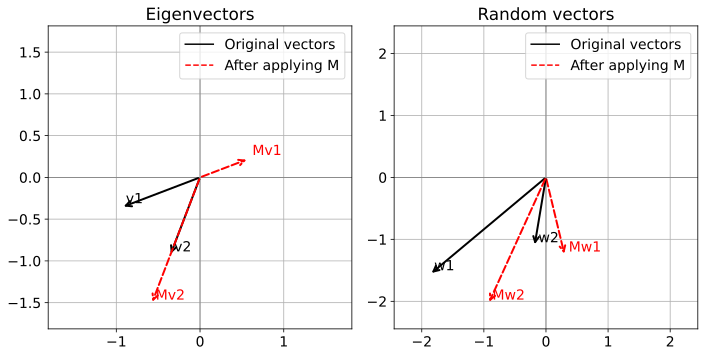

In [5]:
# Generate random vectors for comparison with the eigenvectors.
notEigenvectors = np.random.randn(2, 2)
print("Not eigenvectors:", notEigenvectors)

# Apply the matrix to both sets of vectors.
Mv = M @ eigenvectors
Mw = M @ notEigenvectors

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, vectors, transformed, title, labels in (
        (axes[0], eigenvectors.real, Mv.real, "Eigenvectors", ("v", "Mv")),
        (axes[1], notEigenvectors, Mw, "Random vectors", ("w", "Mw")),
):
    for i in range(vectors.shape[1]):
        vector = vectors[:, i]
        transformed_vector = transformed[:, i]

        ax.annotate(
            "", xy=vector, xytext=(0, 0),
            arrowprops={"arrowstyle": "->", "color": "black", "linewidth": 2},
        )
        ax.annotate(
            f"{labels[0]}{i + 1}", xy=vector, xytext=(4, 4),
            textcoords="offset points", color="black",
        )
        ax.annotate(
            "", xy=transformed_vector, xytext=(0, 0),
            arrowprops={"arrowstyle": "->", "color": "red", "linewidth": 2, "linestyle": "--"},
        )
        ax.annotate(
            f"{labels[1]}{i + 1}", xy=transformed_vector, xytext=(4, 4),
            textcoords="offset points", color="red",
        )

    limit = max(1.2, float(np.max(np.abs(np.concatenate((vectors.ravel(), transformed.ravel()))))) * 1.2)
    ax.set_xlim(-limit, limit)
    ax.set_ylim(-limit, limit)
    ax.axhline(0, color="gray", linewidth=0.8)
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set_aspect("equal", adjustable="box")
    ax.set_title(title)
    ax.grid(True)

axes[0].plot([], [], color="black", label="Original vectors")
axes[0].plot([], [], color="red", linestyle="--", label="After applying M")
axes[0].legend()
axes[1].plot([], [], color="black", label="Original vectors")
axes[1].plot([], [], color="red", linestyle="--", label="After applying M")
axes[1].legend()
plt.tight_layout()
plt.show()


The Matrix with eigenvectors is stretched along the eigenvectors and the eigenvectors are scaled by the eigenvalues. The random vectors are not scaled in the same way, and they are not stretched along their original direction. They are also  rotated. The eigenvectors are the only vectors that are not rotated by the matrix transformation, they are only scaled by the eigenvalues.

# Exercise 4

Diagonalize the matrix A = $\begin{bmatrix} 2 & 0 & 0 \\ 1 & 2 & 1\\ -1 & 0 & 1\end{bmatrix}$.

Find the matrices $\Lambda $ and $V$ such that $A = V \Lambda V^{-1}$


In [8]:
A = np.array([[2, 0, 0],
              [1, 2, 1],
              [-1, 0, 1]])

(eig, V) = np.linalg.eig(A)
print("Eigenvalues:", eig)
print("Eigenvectors (columns of V):\n", V)

assertThat = np.allclose(A, V @ np.diag(eig) @ np.linalg.inv(V))
print("Assertion that A @ V is close to V @ D:", assertThat)



Eigenvalues: [2.+0.j 1.+0.j 2.+0.j]
Eigenvectors (columns of V):
 [[ 0.        +0.j  0.        +0.j  0.70710678+0.j]
 [ 1.        +0.j -0.70710678+0.j  0.        +0.j]
 [ 0.        +0.j  0.70710678+0.j -0.70710678+0.j]]
Assertion that A @ V is close to V @ D: True
D:
 [[2.+0.j 0.+0.j 0.+0.j]
 [0.+0.j 1.+0.j 0.+0.j]
 [0.+0.j 0.+0.j 2.+0.j]]


# Exercise 5

How can you confirm that the diagonalization of matrix A is correct?

Shown above!

Shown in solution to exercise 4

# Exercise 6

If a matrix is symmetric what can we say about its eigenvectors and its eigenvalues?

Try to compute the eigenvalues and eigenvectors for some symmetric matrices. For instance the matrix B, below.

B=$\begin{bmatrix} 1 & 2 & 3 \\ 2 & 1 & 2\\ 3 & 2 & 7\end{bmatrix}$

And test your claims.

The eigen values are real and the eigenvectors for distinct eigenvalues are orthogonal.

The eigenvectors can be chosen to be orthonormal.

Repeated eigenvalues can have eigenvectors that are not orthogonal, but they can be chosen to be orthogonal.

Numpy will produce orthogonal eigenvectors for symmetric matrices.

In [16]:
B = np.array([[1, 2, 3],
              [2, 1, 2],
              [3, 2, 7]])
(eig, V) = np.linalg.eig(B)
print("Eigenvalues:", eig)
print("Eigenvectors (columns of V):\n", V)
assert (np.allclose(V @ V.T, np.eye(3)))
assert (np.allclose(eig.imag, 0))


Eigenvalues: [ 9.09901951+0.j -1.09901951+0.j  1.        +0.j]
Eigenvectors (columns of V):
 [[-0.3967319 +0.j -0.77930077+0.j -0.48507125+0.j]
 [-0.31122211+0.j  0.61133382+0.j -0.72760688+0.j]
 [-0.86356505+0.j  0.13769996+0.j  0.48507125+0.j]]


# Exercise 7

Prove that the eigenvectors of $A^{-1}$ are the same as the eigenvectors of A while the eigenvalues are $\lambda^{-1}$.

The proof follow by writing out the eigendecomposition of $A$ and calculating $A^{-1}$.

$$A=V\Lambda V^{-1}$$
$$A^{-1}=V\Lambda^{-1} V^{-1}$$

# Exercise 8

Compute the solution of Exercises 1 and 2 by hand. And verify the results with numpy.


Let the matrix from Exercise 1 be
$$
A=\begin{bmatrix}a & b \\ c & d\end{bmatrix}
=
\begin{bmatrix}-1 & 1 \\ -1 & 2\end{bmatrix}.
$$

$$(A-\lambda I)v=0$$
that is
$$det(A-\lambda I)=0$$
and then find the v's in the nullspace.

$$
\det(A-\lambda I)
=
\begin{vmatrix}
-1-\lambda & 1 \\
-1 & 2-\lambda
\end{vmatrix}
=
(-1-\lambda)(2-\lambda)+1
=
M = np.array([[-1, 1],
              [-1, 2]])
$$
The roots are $\lambda_1=\frac{1+\sqrt{5}}{2}$ and $\lambda_2=\frac{1-\sqrt{5}}{2}$

Solving $(A-\lambda I)v=0$ for each $\lambda$ gives the eigenvectors

That is, solve
$$
\begin{bmatrix}
-1-\lambda & 1 \\
-1 & 2-\lambda
\end{bmatrix}
\begin{bmatrix}x \\ y\end{bmatrix}
=0
$$

Since the solution $(x,y)$ must be orthogonal two both row vectors of $A-\lambda I$, the row vectors must be parallel, and therefore it is enough to solve one of the equations. And simply choose $x=1$ and solve for y in one of the equations

$$
-1-\lambda + y = 0 \implies y = 1+\lambda
$$

so eigen vectors are $v_1=(1,1+\lambda_1)$ and $v_2=(1,1+\lambda_2)$

We can reconstruct so see if that is correct


In [18]:
A = np.array([[-1, 1],
              [-1, 2]])

lambda1 = (1 + np.sqrt(5)) / 2
lambda2 = (1 - np.sqrt(5)) / 2

print("Eigenvalues:", lambda1, lambda2)
v1 = np.array([1, 1 + lambda1])
v2 = np.array([1, 1 + lambda2])
V = np.column_stack((v1, v2))
D = np.diag([lambda1, lambda2])
assert (np.allclose(A, V @ D @ np.linalg.inv(V)))

Eigenvalues: 1.618033988749895 -0.6180339887498949
